## **Import libraries & load dataset**
## **Q1**

---



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [5]:
df = pd.read_csv('sleep.csv')
df


,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
0,USR-00001,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0,21,84.4,3.20,23.5,22.2,7,10.0,Severe Sleep Debt
1,USR-00002,58,Female,Student,Intermediate,163,YouTube,76,1,92,72,86.7,4.06,18.0,21.5,7,10.0,Severe Sleep Debt
2,USR-00003,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45,23,70.5,3.20,18.1,20.5,7,10.0,Severe Sleep Debt
3,USR-00004,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97,49,38.1,6.99,21.6,22.4,1,1.7,Mild Deficit
4,USR-00005,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0,38,32.3,4.58,24.1,22.8,4,5.3,Moderate Debt
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8495,USR-08496,61,Female,Remote Tech,Night Owl,18,Streaming (Netflix/Hulu),61,1,60,74,21.0,5.57,26.5,18.1,3,3.2,Moderate Debt
8496,USR-08497,64,Male,Student,Night Owl,138,TikTok / Reels,58,1,0,58,84.3,3.99,20.4,19.4,7,10.0,Severe Sleep Debt
8497,USR-08498,34,Male,Corporate 9-to-5,Intermediate,56,Streaming (Netflix/Hulu),56,0,94,33,40.6,7.58,17.4,20.7,2,3.7,Mild Deficit
8498,USR-08499,23,Male,Healthcare / Shift Worker,Night Owl,165,TikTok / Reels,72,0,0,52,123.3,3.20,14.2,15.8,7,10.0,Severe Sleep Debt


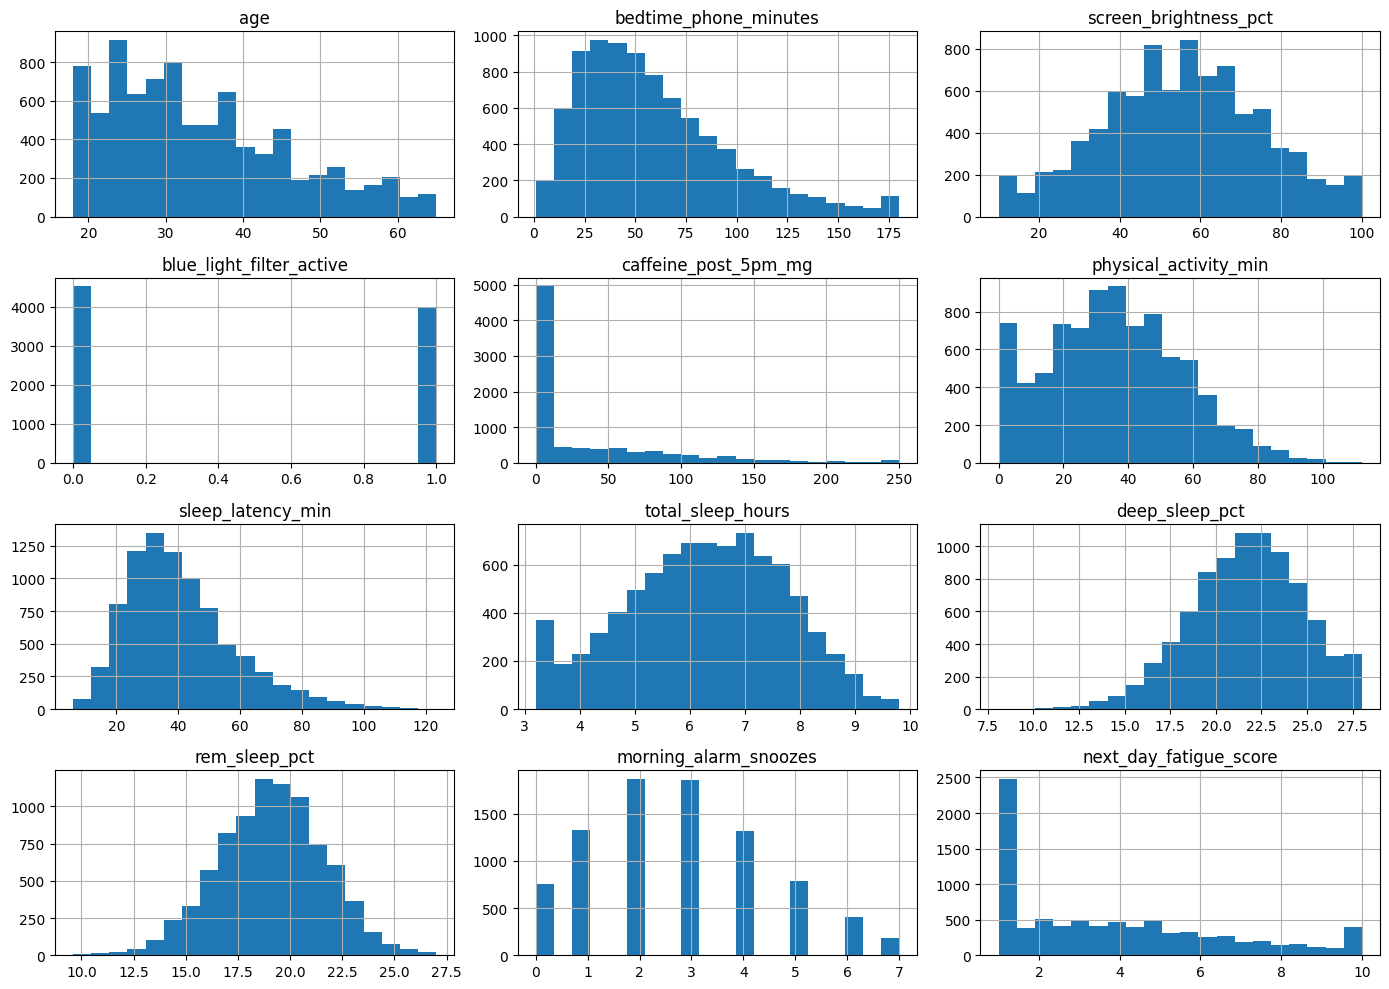

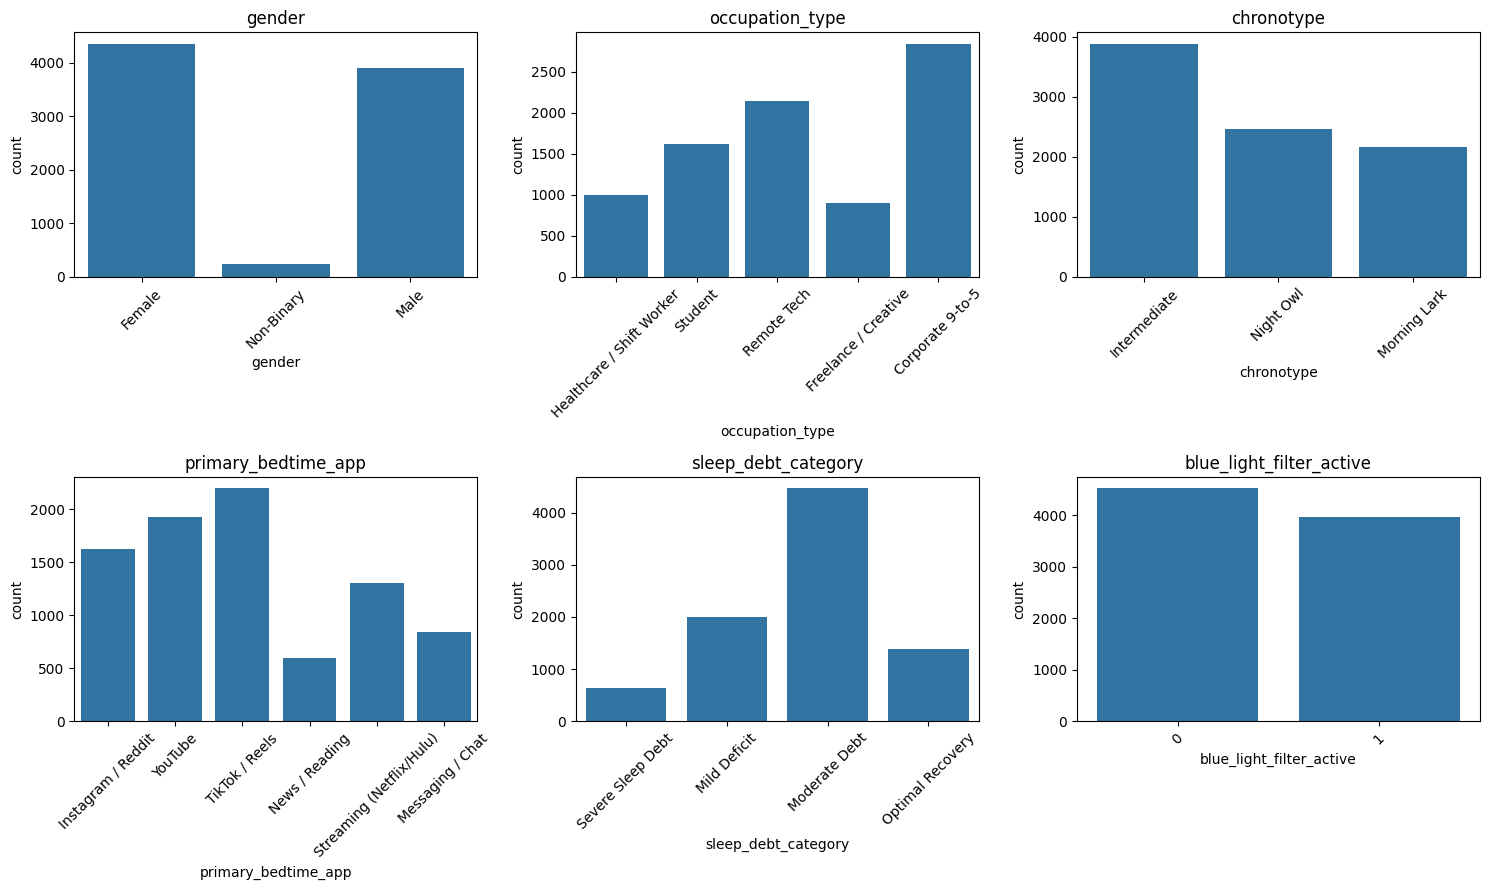

sleep_debt_category
Moderate Debt        4462
Mild Deficit         2004
Optimal Recovery     1387
Severe Sleep Debt     647
Name: count, dtype: int64
sleep_debt_category
Moderate Debt        52.494118
Mild Deficit         23.576471
Optimal Recovery     16.317647
Severe Sleep Debt     7.611765
Name: proportion, dtype: float64


In [6]:
# numeric variables
num_cols = df.select_dtypes(include=np.number).columns

df[num_cols].hist(figsize=(14, 10), bins=20)
plt.tight_layout()
plt.show()

# categorical variables
cat_cols = df.select_dtypes(include='object').columns.drop('user_id')
cat_cols = cat_cols.tolist() + ['blue_light_filter_active']

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for col, ax in zip(cat_cols, axes.flatten()):
    sns.countplot(data=df, x=col, ax=ax)
    ax.set_title(col)
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# imbalance
print(df['sleep_debt_category'].value_counts())
print(df['sleep_debt_category'].value_counts(normalize=True) * 100)

# q1
# το dataset παρουσιάζει ανισσοροπία κλάσεων, η moderate debt εμφανίζεται με ποσοστό 52,49% ενώ η severe sleep debt με ποσόστο μόνο 7,61%. Αρα θα λεγαμε οτι η μετρικη τηε ακρίβειας δεν αποτυπώνει αντιπροσωπεύτικα την απόδοση του μοντέλου


# Q2




In [7]:
df_class = df.drop(columns=['next_day_fatigue_score'])
df_class.shape # done

(8500, 17)

# Q3

In [8]:
# one-hot encoding
df_class = df_class.drop(columns=['user_id'])
cat_cols = ['gender', 'occupation_type', 'chronotype', 'primary_bedtime_app']
df_class = pd.get_dummies(df_class, columns=cat_cols, dtype=int)
df_class.head()

,age,bedtime_phone_minutes,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,...,occupation_type_Student,chronotype_Intermediate,chronotype_Morning Lark,chronotype_Night Owl,primary_bedtime_app_Instagram / Reddit,primary_bedtime_app_Messaging / Chat,primary_bedtime_app_News / Reading,primary_bedtime_app_Streaming (Netflix/Hulu),primary_bedtime_app_TikTok / Reels,primary_bedtime_app_YouTube
0,29,179,54,1,0,21,84.4,3.20,23.5,22.2,...,0,1,0,0,1,0,0,0,0,0
1,58,163,76,1,92,72,86.7,4.06,18.0,21.5,...,1,1,0,0,0,0,0,0,0,1
2,41,100,59,0,45,23,70.5,3.20,18.1,20.5,...,0,0,0,1,0,0,0,0,1,0
3,36,34,52,0,97,49,38.1,6.99,21.6,22.4,...,0,1,0,0,0,0,0,0,0,1
4,23,27,82,1,0,38,32.3,4.58,24.1,22.8,...,0,1,0,0,0,0,0,0,1,0


# Q4



In [9]:
from sklearn.model_selection import train_test_split
# arrays
X = df_class.drop(columns=['sleep_debt_category']).to_numpy()
y = df_class['sleep_debt_category'].to_numpy()

# split
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.10, random_state=0, stratify=y)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_temp, y_temp, test_size=2/9, random_state=0, stratify=y_temp)

print('Train:', X_train.shape, y_train.shape)
print('Validation:', X_valid.shape, y_valid.shape)
print('Test:', X_test.shape, y_test.shape)

Train: (5950, 28) (5950,)
Validation: (1700, 28) (1700,)
Test: (850, 28) (850,)


# Q5


In [10]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score


In [11]:
# z normalization
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_valid_scaled = scaler.transform(X_valid)

# k values
k = [3, 5, 15, 50, int(np.sqrt(len(X_train)))]
weights = ['uniform', 'distance']

results = []
for k in k:
    for w in weights:
      # model
        model = KNeighborsClassifier(n_neighbors=k, weights=w, metric='euclidean')
        model.fit(X_train_scaled, y_train)

        for s, X_set, y_set in [('Train', X_train_scaled, y_train),
                                    ('Validation', X_valid_scaled, y_valid)]:
            y_pred = model.predict(X_set)

            results.append({
                'k': k,
                'weights': w,
                'Set': s,
                'Accuracy': accuracy_score(y_set, y_pred),
                'Precision': precision_score(y_set, y_pred, average='macro', zero_division=0),
                'Recall': recall_score(y_set, y_pred, average='macro', zero_division=0),
                'F1': f1_score(y_set, y_pred, average='macro', zero_division=0),
                'Balanced Acc': balanced_accuracy_score(y_set, y_pred)
            })

results_df = pd.DataFrame(results)


# all val
print('validation')
valid_results = results_df[results_df['Set'] == 'Validation']
display(valid_results.round(5))



validation


,k,weights,Set,Accuracy,Precision,Recall,F1,Balanced Acc
1,3,uniform,Validation,0.70412,0.67900,0.62303,0.64529,0.62303
3,3,distance,Validation,0.70000,0.66680,0.62058,0.63969,0.62058
5,5,uniform,Validation,0.71471,0.72093,0.61861,0.65311,0.61861
7,5,distance,Validation,0.70882,0.70004,0.61470,0.64407,0.61470
9,15,uniform,Validation,0.72647,0.75213,0.60591,0.64622,0.60591
11,15,distance,Validation,0.72412,0.74343,0.60746,0.64591,0.60746
13,50,uniform,Validation,0.74765,0.78251,0.60207,0.64399,0.60207
15,50,distance,Validation,0.74529,0.77858,0.60110,0.64216,0.60110
17,77,uniform,Validation,0.74235,0.77899,0.58058,0.61954,0.58058
19,77,distance,Validation,0.74059,0.77319,0.58521,0.62432,0.58521


In [ ]:
# best
results1 = results_df[results_df['Set'] == 'Validation']
best = results1.loc[results1['F1'].idxmax()]
print('Best KNN')
display(best.to_frame().T.round(5))

Best KNN


,k,weights,Set,Accuracy,Precision,Recall,F1,Balanced Acc
5,5,uniform,Validation,0.714706,0.720927,0.618606,0.653114,0.618606


# Q6


In [ ]:
# merge
X_train_valid = np.concatenate([X_train, X_valid])
y_train_valid = np.concatenate([y_train, y_valid])

# new train set
scaler = StandardScaler()
X_train_valid_scaled = scaler.fit_transform(X_train_valid)
X_test_scaled = scaler.transform(X_test)

# train
best_model = KNeighborsClassifier(n_neighbors=5, weights='uniform', metric='euclidean')
best_model.fit(X_train_valid_scaled, y_train_valid)

# predictions
y_train_valid_pred = best_model.predict(X_train_valid_scaled)
y_test_pred = best_model.predict(X_test_scaled)

# train + validation metrics
train_valid_results = {
    'Set': 'Train+Validation',
    'Accuracy': accuracy_score(y_train_valid, y_train_valid_pred),
    'Precision': precision_score(y_train_valid, y_train_valid_pred, average='macro', zero_division=0),
    'Recall': recall_score(y_train_valid, y_train_valid_pred, average='macro', zero_division=0),
    'F1': f1_score(y_train_valid, y_train_valid_pred, average='macro', zero_division=0),
    'Balanced Acc': balanced_accuracy_score(y_train_valid, y_train_valid_pred)}

# test metrics
test_results = {
    'Set': 'Test',
    'Accuracy': accuracy_score(y_test, y_test_pred),
    'Precision': precision_score(y_test, y_test_pred, average='macro', zero_division=0),
    'Recall': recall_score(y_test, y_test_pred, average='macro', zero_division=0),
    'F1': f1_score(y_test, y_test_pred, average='macro', zero_division=0),
    'Balanced Acc': balanced_accuracy_score(y_test, y_test_pred)}

# compare
comparison = pd.concat([
    results_df[(results_df['k'] == 5) &
               (results_df['weights'] == 'uniform') &
               (results_df['Set'].isin(['Train', 'Validation']))],
    pd.DataFrame([train_valid_results, test_results])], ignore_index=True)

display(comparison.round(3))

,k,weights,Set,Accuracy,Precision,Recall,F1,Balanced Acc
0,5.0,uniform,Train,0.810,0.827,0.737,0.770,0.737
1,5.0,uniform,Validation,0.715,0.721,0.619,0.653,0.619
2,NaN,NaN,Train+Validation,0.811,0.829,0.737,0.770,0.737
3,NaN,NaN,Test,0.718,0.769,0.618,0.663,0.618


# Q7


In [23]:
# 5 fold cross validation

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from scipy import stats

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
k = [3, 5, 15, 50, int(np.sqrt(len(X_temp)))]
weights = ['uniform', 'distance']
scoring = { 'Accuracy': 'accuracy', 'Precision': 'precision_macro', 'Recall': 'recall_macro', 'F1': 'f1_macro', 'Balanced Acc': 'balanced_accuracy'}

# for k

results_cv = []
results_fold = {}

for n in k:
    for w in weights:
        model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=n, weights=w, metric='euclidean')        )

        scores = cross_validate(model, X_temp, y_temp, cv=cv, scoring=scoring)
        results_fold[(n, w)] = scores
        results_cv.append({'k': n, 'weights': w,**{metric: scores['test_' + metric].mean() for metric in scoring}})

results_cv_df = pd.DataFrame(results_cv)
display(results_cv_df.round(4))

## best is k=5, weights=uniform, mean-macro-F1=0.6433
# best accuracy is in k=87, weight=0.7315 but F1=0.5952, δεν βαζιζόμαστε μόνο στο accuracy!

best_cv = results_cv_df.loc[results_cv_df['F1'].idxmax()]
display(best_cv)

# 95% confidence
best_scores = results_fold[(int(best_cv['k']), best_cv['weights'])]
confi_results = []

for metric in scoring:
    values = best_scores['test_' + metric]
    mean = values.mean()

    lower, upper = stats.t.interval(0.95, df=len(values)-1,loc=mean, scale=stats.sem(values))
    confi_results.append({
        'Metric': metric,
        'Mean': mean,
        'CI Lower': lower,
        'CI Upper': upper})

ci_df = pd.DataFrame(confi_results)
display(ci_df.round(4))

# ο καλύτερος συνδιασμός στο 5-fold cv είναι k=5, weight=uniform & mean macro f1 = 0.6433 & 95% CI = [0.661 , 0.6705]
# το balanced accuracy είναι 0,6107 είναι χαμηλότερο από το accuracy0.7082 κάτι που μας δείχνει ότι το μοντέλο δεν αναγνωρίζει το ίδιο καλά ολες τις κλάσεις

# 90-10 model
f_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(
        n_neighbors=int(best_cv['k']),
        weights=best_cv['weights'],
        metric='euclidean'
    )
)

f_model.fit(X_temp, y_temp)
y_test_pred_cv = f_model.predict(X_test)

test_cv_results = {
    'Accuracy': accuracy_score(y_test, y_test_pred_cv),
    'Precision': precision_score(y_test, y_test_pred_cv, average='macro', zero_division=0),
    'Recall': recall_score(y_test, y_test_pred_cv, average='macro', zero_division=0),
    'F1': f1_score(y_test, y_test_pred_cv, average='macro', zero_division=0),
    'Balanced Acc': balanced_accuracy_score(y_test, y_test_pred_cv)
}

display(pd.DataFrame([test_cv_results]).round(4))

,k,weights,Accuracy,Precision,Recall,F1,Balanced Acc
0,3,uniform,0.7037,0.6955,0.6162,0.6429,0.6162
1,3,distance,0.7020,0.6842,0.6142,0.6388,0.6142
2,5,uniform,0.7082,0.7164,0.6107,0.6433,0.6107
3,5,distance,0.7056,0.7003,0.6089,0.6381,0.6089
4,15,uniform,0.7144,0.7464,0.5898,0.6269,0.5898
5,15,distance,0.7190,0.7463,0.5962,0.6334,0.5962
6,50,uniform,0.7307,0.7737,0.5749,0.6110,0.5749
7,50,distance,0.7308,0.7706,0.5794,0.6163,0.5794
8,87,uniform,0.7285,0.7756,0.5565,0.5879,0.5565
9,87,distance,0.7315,0.7768,0.5630,0.5952,0.5630


,2
k,5
weights,uniform
Accuracy,0.708235
Precision,0.716432
Recall,0.610654
F1,0.643329
Balanced Acc,0.610654


,Metric,Mean,CI Lower,CI Upper
0,Accuracy,0.7082,0.6887,0.7278
1,Precision,0.7164,0.6967,0.7361
2,Recall,0.6107,0.5827,0.6386
3,F1,0.6433,0.6161,0.6705
4,Balanced Acc,0.6107,0.5827,0.6386


,Accuracy,Precision,Recall,F1,Balanced Acc
0,0.7176,0.7689,0.6183,0.6635,0.6183


# Q8


In [30]:
#  Nested 5-Fold CV
# outer loop: 3 Folds και 5: inner loop
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline

outer_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=0)
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
# scaler in every fold
model = make_pipeline(StandardScaler(), KNeighborsClassifier(metric='euclidean'))
# 10 of k etc
params = {'kneighborsclassifier__n_neighbors': k,'kneighborsclassifier__weights': weights}

# dokimazei sundiasmous
grid = GridSearchCV(model,param_grid=params,cv=inner_cv,scoring='f1_macro')

# nested cross val
nested_scores = cross_validate(grid, X_temp, y_temp,cv=outer_cv,scoring=scoring)
nested_results = pd.DataFrame({
    metric: nested_scores['test_' + metric]
    for metric in scoring})

nested_results.index = ['Fold 1', 'Fold 2', 'Fold 3']
nested_results.loc['Mean'] = nested_results.mean()
display(nested_results.round(4))



,Accuracy,Precision,Recall,F1,Balanced Acc
Fold 1,0.6973,0.7115,0.5939,0.6270,0.5939
Fold 2,0.6945,0.7050,0.6025,0.6356,0.6025
Fold 3,0.7122,0.7220,0.6094,0.6453,0.6094
Mean,0.7013,0.7128,0.6019,0.6359,0.6019


In [31]:
# parameters chosed by inner cv for every outer cv
nested_scores = cross_validate(grid, X_temp, y_temp,cv=outer_cv,scoring=scoring,return_estimator=True)
for i, model in enumerate(nested_scores['estimator']):
    print(f"Fold {i+1}: {model.best_params_}")

# to nested cv μας έδωσε μέσο accuracy=0.7013 & macroF1=0.6359. Τα νούμερα είναι λίγο χαμηλότερα απο αυτα του 5 fold cv.
# Στα 2/3 outer επιλέχθηκε k=5, ενω στο αλλο k=3.

Fold 1: {'kneighborsclassifier__n_neighbors': 5, 'kneighborsclassifier__weights': 'uniform'}
Fold 2: {'kneighborsclassifier__n_neighbors': 3, 'kneighborsclassifier__weights': 'uniform'}
Fold 3: {'kneighborsclassifier__n_neighbors': 5, 'kneighborsclassifier__weights': 'uniform'}



# Part 2

---



In [36]:
# regression
# prediction : next_day_fatigue_score, knn regression, MAE, RMSE, R^2

df_reg = df.drop(columns=['sleep_debt_category', 'user_id'])
cat_cols = ['gender', 'occupation_type', 'chronotype', 'primary_bedtime_app']
df_reg = pd.get_dummies(df_reg, columns=cat_cols, dtype=int)
X_reg = df_reg.drop(columns=['next_day_fatigue_score']).to_numpy()
y_reg = df_reg['next_day_fatigue_score'].to_numpy()
print(X_reg.shape, y_reg.shape)

# train val test
# 1st 90-10
X_temp_reg, X_test_reg, y_temp_reg, y_test_reg = train_test_split(X_reg, y_reg, test_size=0.10, random_state=0)

# 2nd 70-20
X_train_reg, X_valid_reg, y_train_reg, y_valid_reg = train_test_split(X_temp_reg, y_temp_reg, test_size=2/9, random_state=0)

print('Train:', X_train_reg.shape, y_train_reg.shape)
print('Validation:', X_valid_reg.shape, y_valid_reg.shape)
print('Test:', X_test_reg.shape, y_test_reg.shape)

# no stratify, γιατι η next_day_fatigue_score ειναι συνεχης αριθμητικη τιμη, δεν χρειαζεται. χρησιμοποιουμε απλο τυχαιο διαχωρισμο random_state=0

# knn regression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
# z normalization
scaler_reg = StandardScaler()
X_train_reg_scaled = scaler_reg.fit_transform(X_train_reg)
X_valid_reg_scaled = scaler_reg.transform(X_valid_reg)

# parameters
k = [3, 5, 15, 50, int(np.sqrt(len(X_train_reg)))]
weights = ['uniform', 'distance']
results_reg = []

for n in k:
    for w in weights:
        model = KNeighborsRegressor(n_neighbors=n, weights=w, metric='euclidean')
        model.fit(X_train_reg_scaled, y_train_reg)

        for name, X_set, y_set in [('Train', X_train_reg_scaled, y_train_reg),
                                  ('Validation', X_valid_reg_scaled, y_valid_reg)]:

              y_pred = model.predict(X_set)
              results_reg.append({
                'k': n,
                'weights': w,
                'Set': name,
                'MAE': mean_absolute_error(y_set, y_pred),
                'RMSE': np.sqrt(mean_squared_error(y_set, y_pred)),
                'R2': r2_score(y_set, y_pred)

                })

results_reg_df = pd.DataFrame(results_reg)

print('train results')
display(results_reg_df[results_reg_df['Set'] == 'Train'].round(4))

print('val results')
valid_reg = results_reg_df[results_reg_df['Set'] == 'Validation']
display(valid_reg.round(4))

best_reg = valid_reg.loc[valid_reg['MAE'].idxmin()]

print('best')
display(best_reg.to_frame().T)

# best: k=5, weights=distance with val MAe=0.8505, RMSE=1.1345 kai R2=0.8238. Η επιλογη του μοντελου βασίζεται στο val MAE

# next step

# merge
X_train_valid_reg = np.concatenate([X_train_reg, X_valid_reg])
y_train_valid_reg = np.concatenate([y_train_reg, y_valid_reg])

scaler_reg = StandardScaler()
X_train_valid_reg_scaled = scaler_reg.fit_transform(X_train_valid_reg)
X_test_reg_scaled = scaler_reg.transform(X_test_reg)

# train best model
best_model_reg = KNeighborsRegressor(n_neighbors=5, weights='distance', metric='euclidean')
best_model_reg.fit(X_train_valid_reg_scaled, y_train_valid_reg)

# predictions
y_train_valid_pred_reg = best_model_reg.predict(X_train_valid_reg_scaled)
y_test_pred_reg = best_model_reg.predict(X_test_reg_scaled)

# results
comparison_reg = pd.DataFrame([{'Set': 'Train+Validation',
     'MAE': mean_absolute_error(y_train_valid_reg, y_train_valid_pred_reg),
     'RMSE': np.sqrt(mean_squared_error(y_train_valid_reg, y_train_valid_pred_reg)),
     'R2': r2_score(y_train_valid_reg, y_train_valid_pred_reg)},
    {'Set': 'Test',
     'MAE': mean_absolute_error(y_test_reg, y_test_pred_reg),
     'RMSE': np.sqrt(mean_squared_error(y_test_reg, y_test_pred_reg)),
     'R2': r2_score(y_test_reg, y_test_pred_reg)}])

display(comparison_reg.round(4))

# to test mae = 0.8393 ειναι πολυ κοντα στο validation mae = 0.8505 και το test r2 = 0.8294 λίγο πιο υψηλο. Το μοντελο έχει καλη αποδοση σε new data. Τα νουμερα στο trian+val οφειλωνται στο distance weights.


(8500, 28) (8500,)
Train: (5950, 28) (5950,)
Validation: (1700, 28) (1700,)
Test: (850, 28) (850,)
train results


,k,weights,Set,MAE,RMSE,R2
0,3,uniform,Train,0.6310,0.8625,0.8961
2,3,distance,Train,0.0000,0.0000,1.0000
4,5,uniform,Train,0.7081,0.9461,0.8749
6,5,distance,Train,0.0000,0.0000,1.0000
8,15,uniform,Train,0.8424,1.0759,0.8383
10,15,distance,Train,0.0000,0.0000,1.0000
12,50,uniform,Train,0.9262,1.1577,0.8127
14,50,distance,Train,0.0000,0.0000,1.0000
16,77,uniform,Train,0.9552,1.1883,0.8027
18,77,distance,Train,0.0000,0.0000,1.0000


val results


,k,weights,Set,MAE,RMSE,R2
1,3,uniform,Validation,0.8773,1.1890,0.8065
3,3,distance,Validation,0.8679,1.1785,0.8099
5,5,uniform,Validation,0.8620,1.1489,0.8193
7,5,distance,Validation,0.8505,1.1345,0.8238
9,15,uniform,Validation,0.8906,1.1367,0.8231
11,15,distance,Validation,0.8748,1.1194,0.8285
13,50,uniform,Validation,0.9347,1.1658,0.8140
15,50,distance,Validation,0.9220,1.1516,0.8184
17,77,uniform,Validation,0.9569,1.1928,0.8052
19,77,distance,Validation,0.9448,1.1788,0.8098


best


,k,weights,Set,MAE,RMSE,R2
7,5,distance,Validation,0.8505,1.134507,0.823809


,Set,MAE,RMSE,R2
0,Train+Validation,0.0000,0.0000,1.0000
1,Test,0.8393,1.1218,0.8294


In [43]:
# 5 fold cv

from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import make_pipeline
from scipy import stats

cv_reg = KFold(n_splits=5, shuffle=True, random_state=0) # no stratified
k = [3, 5, 15, 50, int(np.sqrt(len(X_temp_reg)))]
weights = ['uniform', 'distance']
scoring_reg = {'MAE': 'neg_mean_absolute_error','RMSE': 'neg_root_mean_squared_error','R2': 'r2'}

results_cv_reg = []
results_fold_reg = {}

for n in k:
    for w in weights:
        model = make_pipeline(StandardScaler(),KNeighborsRegressor(n_neighbors=n, weights=w, metric='euclidean'))

        scores = cross_validate(model, X_temp_reg, y_temp_reg,cv=cv_reg, scoring=scoring_reg)
        results_fold_reg[(n, w)] = scores
        results_cv_reg.append({
            'k': n,
            'weights': w,
            'MAE': -scores['test_MAE'].mean(),
            'RMSE': -scores['test_RMSE'].mean(),
            'R2': scores['test_R2'].mean()})

results_cv_reg_df = pd.DataFrame(results_cv_reg)
display(results_cv_reg_df.round(4))

# best k=5 weights=distance, MAE=0.8652, RMSE=1.1518, R2=0.8153
best_cv_reg = results_cv_reg_df.loc[results_cv_reg_df['MAE'].idxmin()]
display(best_cv_reg)

# 95% confidence
best_scores_reg = results_fold_reg[(int(best_cv_reg['k']), best_cv_reg['weights'])]

confi_results_reg = []
for metric in scoring_reg:
    values = best_scores_reg['test_' + metric]

    if metric in ['MAE', 'RMSE']:
        values = -values

    mean = values.mean()
    lower, upper = stats.t.interval(0.95, df=len(values)-1,loc=mean, scale=stats.sem(values))

    confi_results_reg.append({
        'Metric': metric,
        'Mean': mean,
        'CI Lower': lower,
        'CI Upper': upper
    })

confi_df_reg = pd.DataFrame(confi_results_reg)
display(confi_df_reg.round(4))

# besti in 5-fold CV is k=5, weights=distance, mean MAE 0.8652, 95% confidence [0.8388,0.8917], mean RMSE 1.1518 and R2 0.8153


,k,weights,MAE,RMSE,R2
0,3,uniform,0.8991,1.2154,0.7943
1,3,distance,0.8899,1.2045,0.7980
2,5,uniform,0.8768,1.1654,0.8110
3,5,distance,0.8652,1.1518,0.8153
4,15,uniform,0.8975,1.1490,0.8162
5,15,distance,0.8822,1.1316,0.8218
6,50,uniform,0.9427,1.1787,0.8066
7,50,distance,0.9292,1.1640,0.8114
8,87,uniform,0.9736,1.2106,0.7960
9,87,distance,0.9608,1.1964,0.8008


,3
k,5
weights,distance
MAE,0.865227
RMSE,1.151831
R2,0.815322


,Metric,Mean,CI Lower,CI Upper
0,MAE,0.8652,0.8388,0.8917
1,RMSE,1.1518,1.1136,1.1901
2,R2,0.8153,0.8029,0.8278


In [46]:
# nested cross val
from sklearn.model_selection import GridSearchCV

outer_cv_reg = KFold(n_splits=3, shuffle=True, random_state=0)
inner_cv_reg = KFold(n_splits=5, shuffle=True, random_state=0)

model_reg = make_pipeline(StandardScaler(),KNeighborsRegressor(metric='euclidean'))
params_reg = {'kneighborsregressor__n_neighbors': k,'kneighborsregressor__weights': weights}
grid_reg = GridSearchCV(model_reg,param_grid=params_reg,cv=inner_cv_reg,scoring='neg_mean_absolute_error')

# nested cv regression
nested_scores_reg = cross_validate(grid_reg, X_temp_reg, y_temp_reg,cv=outer_cv_reg,scoring=scoring_reg,return_estimator=True)

# results for the outer folds
nested_results_reg = pd.DataFrame({
    'MAE': -nested_scores_reg['test_MAE'],
    'RMSE': -nested_scores_reg['test_RMSE'],
    'R2': nested_scores_reg['test_R2']
})

nested_results_reg.index = ['Fold 1', 'Fold 2', 'Fold 3']
nested_results_reg.loc['Mean'] = nested_results_reg.mean()
display(nested_results_reg.round(4))

# best
for i, model in enumerate(nested_scores_reg['estimator']):
    print(f"Fold {i+1}: {model.best_params_}")

    # best fold1-2 k=5 and fold3 k=15, all distance
    # nested cv mean MAE=0.8863, rmse=1.1632 and r2=0.8118

,MAE,RMSE,R2
Fold 1,0.8730,1.1544,0.8170
Fold 2,0.8836,1.1862,0.8038
Fold 3,0.9023,1.1491,0.8145
Mean,0.8863,1.1632,0.8118


Fold 1: {'kneighborsregressor__n_neighbors': 5, 'kneighborsregressor__weights': 'distance'}
Fold 2: {'kneighborsregressor__n_neighbors': 5, 'kneighborsregressor__weights': 'distance'}
Fold 3: {'kneighborsregressor__n_neighbors': 15, 'kneighborsregressor__weights': 'distance'}
